# Lab-2: Exploratory Data Analysis (EDA) & Digital Conversion Funnel Analysis using Python

**Course:** DS 4115  
**Prepared:** 2026-11-15  



In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Environment successfully set up!")
print(f"pandas version:  {pd.__version__}")
print(f"NumPy version:   {np.__version__}")
print(f"seaborn version: {sns.__version__}")


Environment successfully set up!
pandas version:  2.2.3
NumPy version:   2.4.6
seaborn version: 0.13.2


## Part 1: Generating and Loading Digital Session Logs

The script below generates 5,000 synthetic GA4-style session records with user IDs, device categories, funnel flags, page views, and time spent on site. A fixed random seed (`42`) makes the dataset and all downstream results reproducible.


In [2]:
np.random.seed(42)
n_rows = 5000

session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(['desktop', 'mobile', 'tablet'], size=n_rows, p=[0.5, 0.4, 0.1])

session_start_flag = np.ones(n_rows, dtype=int)
add_to_cart_flag = np.random.choice([0, 1], size=n_rows, p=[0.7, 0.3])
purchase_flag = np.where(add_to_cart_flag == 1, np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]), 0)

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

DATA_FILE = Path.cwd() / 'ga4_sample_session_logs.csv'
df.to_csv(DATA_FILE, index=False)

print(f"Dataset '{DATA_FILE.name}' successfully generated and loaded!")
print(f"Saved at: {DATA_FILE.resolve()}")
df.head()


Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!
Saved at: /content/ga4_sample_session_logs.csv


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


## Part 1, Step 2: Inspect Dataset Structure

Checking dimensions, column types, and non-null counts is a standard first step before analysis.


In [3]:
print("Dataset shape (rows, columns):", df.shape)
df.info()


Dataset shape (rows, columns): (5000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   object 
 1   user_id             5000 non-null   object 
 2   device_category     5000 non-null   object 
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), object(3)
memory usage: 312.6+ KB


## Part 2: Constructing the Digital Conversion Funnel

The funnel tracks progression through three milestones:

**Session start → Add to cart → Purchase**

Two views are useful:
1. **Conversion rate** = users at each step ÷ total sessions.
2. **Step-to-step retention** = users at the current step ÷ users at the immediately preceding step.

The corresponding drop-off rate is `100% − step-to-step retention`.


In [4]:
total_sessions = df['session_id'].nunique()
sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()
sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()

funnel_data = {
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
}
funnel_df = pd.DataFrame(funnel_data)

funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100
funnel_df['Step-to-Step Retention (%)'] = funnel_df['User Sessions'].pct_change().fillna(1) * 100
funnel_df['Drop-off from Prior Step (%)'] = 100 - funnel_df['Step-to-Step Retention (%)']

print(funnel_df.to_string(index=False))
funnel_df


     Funnel Step  User Sessions  Conversion Rate (%)  Step-to-Step Retention (%)  Drop-off from Prior Step (%)
1. Session Start           5000                100.0                  100.000000                      0.000000
  2. Add to Cart           1470                 29.4                  -70.600000                    170.600000
     3. Purchase            905                 18.1                  -38.435374                    138.435374


,Funnel Step,User Sessions,Conversion Rate (%),Step-to-Step Retention (%),Drop-off from Prior Step (%)
0,1. Session Start,5000,100.0,100.000000,0.000000
1,2. Add to Cart,1470,29.4,-70.600000,170.600000
2,3. Purchase,905,18.1,-38.435374,138.435374


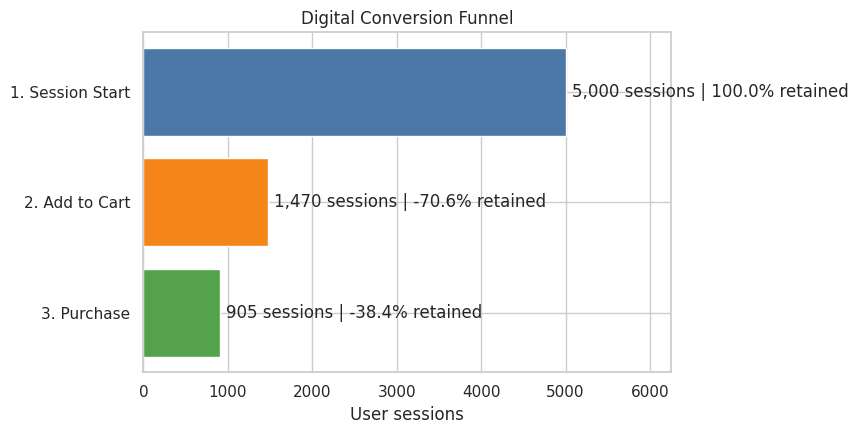

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = ['#4C78A8', '#F58518', '#54A24B']
bars = ax.barh(funnel_df['Funnel Step'], funnel_df['User Sessions'], color=colors)
ax.invert_yaxis()
ax.set_xlim(0, funnel_df['User Sessions'].max() * 1.25)
ax.set_xlabel('User sessions')
ax.set_title('Digital Conversion Funnel')

for bar, sessions, retention in zip(bars, funnel_df['User Sessions'], funnel_df['Step-to-Step Retention (%)']):
    ax.text(bar.get_width() + 75, bar.get_y() + bar.get_height() / 2,
            f'{sessions:,} sessions | {retention:.1f}% retained', va='center')

plt.tight_layout()
plt.show()


## Part 3: Data Cleaning & Handling Missing Values

Real-world telemetry data is often messy. This section first detects missing values and then performs median imputation for the numeric time-on-site field. Categorical text is standardized to lowercase and stripped of leading/trailing whitespace.


In [6]:
missing_counts = df.isnull().sum()

print("Missing values by column:")
print(missing_counts)
print(f"Total missing cells: {int(missing_counts.sum())}")
print(f"Rows affected in time_on_site_sec: {int(df['time_on_site_sec'].isna().sum())}")

missing_counts[missing_counts > 0]


Missing values by column:
session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64
Total missing cells: 50
Rows affected in time_on_site_sec: 50


,0
time_on_site_sec,50


In [7]:
time_missing_before = int(df['time_on_site_sec'].isna().sum())

median_time = df['time_on_site_sec'].median()
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

rows_before_session_drop = len(df)
df = df.dropna(subset=['session_id'])

df['device_category'] = df['device_category'].str.lower().str.strip()

print("Data cleaning completed.")
print(f"Median imputed into time_on_site_sec: {median_time:.0f} seconds")
print(f"Rows affected by session_id cleanup: {rows_before_session_drop - len(df)}")
print("Missing values remaining:", int(df.isnull().sum().sum()))
df.head()


Data cleaning completed.
Median imputed into time_on_site_sec: 144 seconds
Rows affected by session_id cleanup: 0
Missing values remaining: 0


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


In [8]:
print("Post-cleaning descriptive statistics:")
print(df.describe().round(2))

print("Device category mix:")
device_counts = df['device_category'].value_counts()
device_percent = (df['device_category'].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({'Sessions': device_counts, 'Share (%)': device_percent}))


Post-cleaning descriptive statistics:
       session_start_flag  add_to_cart_flag  purchase_flag  page_views  \
count              5000.0           5000.00        5000.00     5000.00   
mean                  1.0              0.29           0.18        4.02   
std                   0.0              0.46           0.39        1.72   
min                   1.0              0.00           0.00        1.00   
25%                   1.0              0.00           0.00        3.00   
50%                   1.0              0.00           0.00        4.00   
75%                   1.0              1.00           0.00        5.00   
max                   1.0              1.00           1.00       12.00   

       time_on_site_sec  
count           5000.00  
mean             158.58  
std               85.10  
min               20.00  
25%               96.00  
50%              144.00  
75%              205.00  
max              616.00  
Device category mix:
                 Sessions  Share (%)
dev

## Part 4: Exploratory Data Analysis & Correlation Heatmap

Correlation analysis measures the linear association between numerical variables. The heatmap below is used to assess which engagement metrics move together and which are associated with conversion behavior.

> **Note:** `session_start_flag` is constant at 1 for every generated session. A Pearson correlation coefficient is undefined when one variable has zero variance, so its correlations appear as `NaN`.


In [9]:
numeric_cols = ['session_start_flag', 'add_to_cart_flag', 'purchase_flag', 'page_views', 'time_on_site_sec']
corr_matrix = df[numeric_cols].corr()

print(corr_matrix.round(4))
corr_matrix


                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN            1.0000         0.7285   
purchase_flag                      NaN            0.7285         1.0000   
page_views                         NaN           -0.0110        -0.0006   
time_on_site_sec                   NaN            0.0018         0.0042   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag       -0.0110            0.0018  
purchase_flag          -0.0006            0.0042  
page_views              1.0000            0.8041  
time_on_site_sec        0.8041            1.0000  


,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
session_start_flag,NaN,NaN,NaN,NaN,NaN
add_to_cart_flag,NaN,1.000000,0.728494,-0.010963,0.001849
purchase_flag,NaN,0.728494,1.000000,-0.000583,0.004230
page_views,NaN,-0.010963,-0.000583,1.000000,0.804072
time_on_site_sec,NaN,0.001849,0.004230,0.804072,1.000000


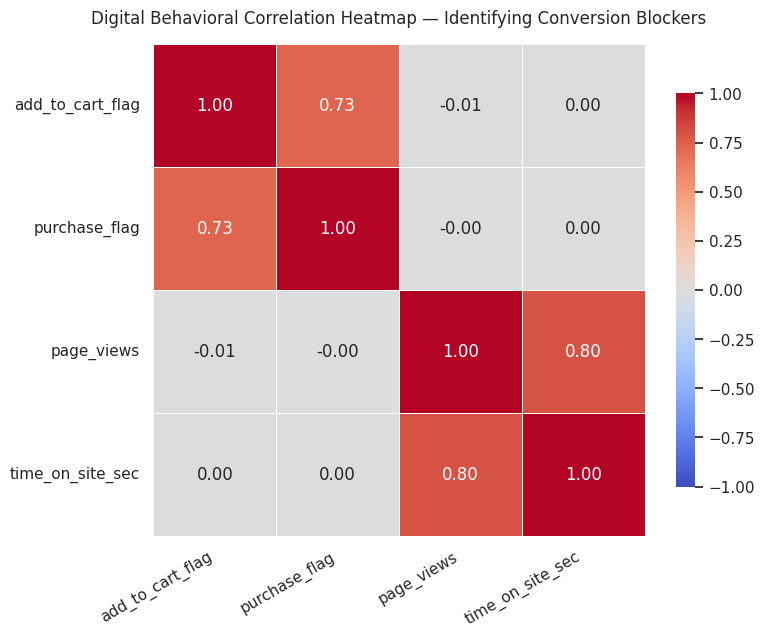

In [13]:
corr_clean = corr_matrix.dropna(how='all', axis=0).dropna(how='all', axis=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.grid(False)

sns.heatmap(
    corr_clean,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=ax
)

ax.set_title(
    'Digital Behavioral Correlation Heatmap — Identifying Conversion Blockers',
    fontsize=12,
    pad=15
)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
device_funnel = (df.groupby('device_category')
      .agg(Sessions=('session_id', 'nunique'), Add_to_Cart=('add_to_cart_flag', 'sum'), Purchases=('purchase_flag', 'sum')))

device_funnel['Session-to-Cart (%)'] = device_funnel['Add_to_Cart'] / device_funnel['Sessions'] * 100
device_funnel['Cart-to-Purchase (%)'] = device_funnel['Purchases'] / device_funnel['Add_to_Cart'] * 100
device_funnel['Session-to-Purchase (%)'] = device_funnel['Purchases'] / device_funnel['Sessions'] * 100

print(device_funnel.round(2))
device_funnel


                 Sessions  Add_to_Cart  Purchases  Session-to-Cart (%)  \
device_category                                                          
desktop              2547          755        474                29.64   
mobile               1958          565        344                28.86   
tablet                495          150         87                30.30   

                 Cart-to-Purchase (%)  Session-to-Purchase (%)  
device_category                                                 
desktop                         62.78                    18.61  
mobile                          60.88                    17.57  
tablet                          58.00                    17.58  


,Sessions,Add_to_Cart,Purchases,Session-to-Cart (%),Cart-to-Purchase (%),Session-to-Purchase (%)
device_category,,,,,,
desktop,2547,755,474,29.642717,62.781457,18.610130
mobile,1958,565,344,28.855975,60.884956,17.568948
tablet,495,150,87,30.303030,58.000000,17.575758


In [12]:
assert df.shape == (5000, 8), f"Unexpected dataset shape: {df.shape}"
assert int(df.isnull().sum().sum()) == 0, "Missing values remain after cleaning"
assert sorted(df['device_category'].unique().tolist()) == ['desktop', 'mobile', 'tablet']
assert funnel_df['User Sessions'].tolist() == [5000, 1470, 905]
assert DATA_FILE.exists(), "CSV output file was not created"

print("All notebook checks passed.")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Missing cells: {int(df.isnull().sum().sum())}")
print(f"Funnel sessions: {funnel_df['User Sessions'].tolist()}")
print(f"CSV verified: {DATA_FILE.resolve()}")


All notebook checks passed.
Rows: 5,000 | Columns: 8 | Missing cells: 0
Funnel sessions: [5000, 1470, 905]
CSV verified: /content/ga4_sample_session_logs.csv


## Observations and Conclusion

### Key observations

1. **Dataset:** 5,000 synthetic GA4-style sessions and 8 fields were generated reproducibly with random seed 42.
2. **Device mix:** Desktop accounts for 2,547 sessions (50.94%), mobile for 1,958 (39.16%), and tablet for 495 (9.90%).
3. **Data hygiene:** Exactly 50 missing values occurred in `time_on_site_sec`; no other columns had missing entries. Median imputation used **144 seconds**, and the cleaned dataset contains zero missing cells.
4. **Funnel:** The session count progresses from **5,000 → 1,470 → 905**.
   - Session-to-add-to-cart conversion: **29.40%**
   - Add-to-cart-to-purchase retention: **61.56%**
   - Overall session-to-purchase conversion: **18.10%**
   - Drop-off is **70.60%** from session start to add to cart and **38.44%** from add to cart to purchase.
5. **Primary conversion blocker:** The first transition is the largest bottleneck because 70.60% of sessions never reach add to cart. The second-largest issue is the 38.44% purchase-stage drop-off among users who added an item.
6. **Correlations:** `add_to_cart_flag` and `purchase_flag` have a strong positive correlation of **0.7285**, as expected in a sequential funnel. `page_views` and `time_on_site_sec` correlate at **0.8041**. However, page views and time on site have near-zero correlations with purchase, suggesting that engagement depth alone did not drive conversion in this synthetic dataset.
7. **Device diagnostic:** Session-to-purchase rates are similar across desktop (18.61%), mobile (17.57%), and tablet (17.58%), so device category does not appear to be the main blocker.
8. **Caveat:** These findings describe associations in synthetic data; they do not establish causation. Real GA4 data would also require timestamps, acquisition channels, product details, and other context.

### Bottom line

The clearest priority is to diagnose and improve the **session-start-to-add-to-cart** transition—for example, by evaluating product discoverability, page messaging, calls to action, loading performance, and checkout-entry friction. The completed notebook and companion report contain the full analysis and the generated CSV.
